# Step 2b — Validate the soil-suitability layer against an independent product

Checks the soil-only layer built in `2.a)` against GAEZ v4 (FAO/IIASA) `SQ0` — its own
most-limiting soil-quality index, built from a different HWSD vintage (v1.2) with FAO's
own rating rules — as an independent, non-circular check (this pipeline's soil layer is
built from Sys et al. 1993 tables on HWSD2, entirely separately). **No climate component
anywhere in this notebook** — see `5_Suitability_climate_soil_combined_validation/5.a)_Apply_ERA5_validation_threshold5pct/5.a)` for the
combined climate×soil map and its own validation.

Maize only: no soil-only suitability product for wheat was found publicly downloadable
(GAEZ's ready-made `SQ0` GeoTIFF exists only for maize; wheat's own soil-only sub-index is
not exposed as a static file in GAEZ's data repository — only its combined climate+soil+
terrain suitability is, which is a different comparison, done in `5.a)` instead).

In [1]:
import os; os.environ.setdefault("HDF5_USE_FILE_LOCKING", "FALSE")   # BDAP/EOS refuses HDF5 file locks ("NetCDF: HDF error")
# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  PARAMÈTRES — modifier ici, puis relancer les cellules marquées [RUN]  ║
# ╚══════════════════════════════════════════════════════════════════════════╝
import warnings; warnings.filterwarnings('ignore')
import numpy as np, xarray as xr, rasterio
from rasterio.windows import Window
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr

BASE      = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "0_Input_data").is_dir())  # racine du projet (local ou BDAP)
import sys; sys.path.insert(0, str(BASE)); import crop_utils as cu   # helpers + config reader (project root)
CFG = cu.load_config()   # config/config_<profile>.json, written by 00_config_and_inventory.ipynb
SOIL_NC   = BASE / "1_SVM" / "2_soil_suitability" / "soil_suitability_outputs" / "soil_suitability_HWSD_1deg.nc"
GAEZ_DIR  = BASE / "0_Input_data" / "gaez"
GAEZ_H    = GAEZ_DIR / "SQ0_mze_v9aH.tif"   # high-input management
GAEZ_L    = GAEZ_DIR / "SQ0_mze_v9aL.tif"   # low-input management
OUT_DIR   = BASE / "1_SVM" / "2_soil_suitability" / "soil_validation_outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

CROP = 'Maize_rf'

print("Input files:")
for p in [SOIL_NC, GAEZ_H, GAEZ_L]:
    print(f'  {"OK" if p.exists() else "MISSING"}: {p}')

Input files:
  OK: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\2_soil_suitability\soil_suitability_outputs\soil_suitability_HWSD_1deg.nc
  OK: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\0_Input_data\gaez\SQ0_mze_v9aH.tif
  OK: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\0_Input_data\gaez\SQ0_mze_v9aL.tif


In [2]:
ds_grid = xr.open_dataset(SOIL_NC)
target_lats_asc = ds_grid.lat.values
target_lons     = ds_grid.lon.values
land_mask = np.isfinite(ds_grid[f"soil_suit_idx_{CROP}"].values)   # land = where the soil layer exists
ds_grid.close()

nlat, nlon = len(target_lats_asc), len(target_lons)
LAT_MIN_EDGE, LAT_MAX_EDGE = target_lats_asc[0] - 0.5, target_lats_asc[-1] + 0.5
LON_MIN_EDGE, LON_MAX_EDGE = target_lons[0] - 0.5, target_lons[-1] + 0.5
ext = [LON_MIN_EDGE, LON_MAX_EDGE, LAT_MIN_EDGE, LAT_MAX_EDGE]

print(f"Grid: {nlat} lat x {nlon} lon, {land_mask.sum()} land cells")


Grid: 37 lat x 70 lon, 1221 land cells


In [3]:
# Country/coastline outlines (Natural Earth via regionmask -> geopandas), so a big real
# feature like the Gulf of Bothnia isn't mistaken for missing/incorrect land coverage.
import regionmask
_countries_gdf = regionmask.defined_regions.natural_earth_v5_0_0.countries_10.to_geodataframe()
_countries_gdf = _countries_gdf.cx[LON_MIN_EDGE-2:LON_MAX_EDGE+2, LAT_MIN_EDGE-2:LAT_MAX_EDGE+2]

def add_coastlines(ax, color='black', linewidth=0.4):
    _countries_gdf.boundary.plot(ax=ax, color=color, linewidth=linewidth, zorder=5)
    ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3])

## Soil-only layer vs GAEZ SQ0

GAEZ's `SQ0` raster (5 arc-min, global) stores 14 integer codes: 0-9 are suitability
classes in 0.1-wide bands (`0` = 0.0-0.1 ... `9` = 0.9-1.0), and 10-13 are special
categories (Permafrost, Not evaluated, Water, plus an unused 14th bin) that are not a
suitability score and are masked to NaN here. Codes 0-9 are converted to a continuous
score via the **band midpoint** ((code+0.5)/10).

Regridded to our 1° grid by **area-weighted block average of the rating**, not by
averaging the raw GAEZ pixels first and rating the average — the same principle used
throughout Step 2a (rate fine, then aggregate) — over its native 12x12 sub-pixels per 1°
cell (5 arc-min = 1/12 degree).

In [4]:
def load_gaez_sq0(path):
    """Read GAEZ SQ0 (5 arc-min, global), clip to our domain, decode codes 0-9 to a continuous
    0-1 score (band midpoint), mask codes 10-13 (Permafrost/Not evaluated/Water/unused) and the
    raster's own nodata to NaN, then area-average (block mean of the rating) to our 1deg grid."""
    with rasterio.open(path) as src:
        res = src.transform.a
        ulx, uly = src.transform.c, src.transform.f
        nodata = src.nodata
        px_per_deg = round(1.0 / res)
        col_start = round((LON_MIN_EDGE - ulx) / res)
        row_start = round((uly - LAT_MAX_EDGE) / res)
        col_count = round((LON_MAX_EDGE - LON_MIN_EDGE) / res)
        row_count = round((LAT_MAX_EDGE - LAT_MIN_EDGE) / res)
        raw = src.read(1, window=Window(col_start, row_start, col_count, row_count))

    score = np.where(raw <= 9, (raw.astype(float) + 0.5) / 10.0, np.nan)
    if nodata is not None:
        score[raw == nodata] = np.nan

    assert score.shape == (nlat * px_per_deg, nlon * px_per_deg), (
        "GAEZ window does not tile evenly into the 1deg grid -- check GAEZ_H/GAEZ_L extent.")
    blocks = score.reshape(nlat, px_per_deg, nlon, px_per_deg)
    with np.errstate(invalid='ignore'):
        out = np.nanmean(blocks, axis=(1, 3))[::-1, :]   # native row 0 = north -> flip to ascending lat
    return np.where(land_mask, out, np.nan)

gaez_H = load_gaez_sq0(GAEZ_H)
gaez_L = load_gaez_sq0(GAEZ_L)
print(f'GAEZ SQ0 (maize), high input: mean over land = {np.nanmean(gaez_H[land_mask]):.3f}, '
      f'{int(np.sum(np.isnan(gaez_H) & land_mask))} land cells with no rating (Permafrost/Not evaluated/Water)')
print(f'GAEZ SQ0 (maize), low input:  mean over land = {np.nanmean(gaez_L[land_mask]):.3f}, '
      f'{int(np.sum(np.isnan(gaez_L) & land_mask))} land cells with no rating')

GAEZ SQ0 (maize), high input: mean over land = 0.604, 10 land cells with no rating (Permafrost/Not evaluated/Water)
GAEZ SQ0 (maize), low input:  mean over land = 0.582, 9 land cells with no rating


In [5]:
ds_soil = xr.open_dataset(SOIL_NC)
our_idx = ds_soil[f'soil_suit_idx_{CROP}'].values
ds_soil.close()

both = np.isfinite(our_idx) & np.isfinite(gaez_H) & land_mask
r_H = np.corrcoef(our_idx[both], gaez_H[both])[0, 1]
rho_H = spearmanr(our_idx[both], gaez_H[both]).correlation
rmse_H = float(np.sqrt(np.mean((our_idx[both] - gaez_H[both])**2)))
bias_H = float(np.mean(our_idx[both] - gaez_H[both]))
print(f'Our index vs GAEZ SQ0 (high input), {both.sum()} common land cells:')
print(f'  Pearson r = {r_H:.3f}, Spearman rho = {rho_H:.3f}, RMSE = {rmse_H:.3f}, bias (ours-GAEZ) = {bias_H:+.3f}')

both_L = np.isfinite(our_idx) & np.isfinite(gaez_L) & land_mask
r_L = np.corrcoef(our_idx[both_L], gaez_L[both_L])[0, 1]
rho_L = spearmanr(our_idx[both_L], gaez_L[both_L]).correlation
print(f'Our index vs GAEZ SQ0 (low input),  {both_L.sum()} common land cells: Pearson r = {r_L:.3f}, Spearman rho = {rho_L:.3f}')

# Coastal cells are where our HWSD2-derived land mask and GAEZ's own (5 arc-min) coastline
# disagree most: a 1deg cell can be mostly land in one product and mostly sea in the other,
# which shows up as large red/blue mismatches along the coast in the difference map above.
# Split by land_frac (fraction of HWSD2 sub-pixels that are land) to separate that effect
# from genuine inland disagreement.
ds_land = xr.open_dataset(SOIL_NC)
land_frac = ds_land['land_frac'].values if 'land_frac' in ds_land else None
ds_land.close()
if land_frac is not None:
    interior = both & (land_frac >= 0.5)
    coastal  = both & (land_frac < 0.5)
    r_int = np.corrcoef(our_idx[interior], gaez_H[interior])[0, 1]
    r_co  = np.corrcoef(our_idx[coastal],  gaez_H[coastal])[0, 1] if coastal.sum() > 1 else np.nan
    print('Split by land fraction (high input):')
    print(f'  Interior cells (land_frac >= 0.5): n={int(interior.sum())}, Pearson r = {r_int:.3f}')
    print(f'  Coastal cells  (land_frac <  0.5): n={int(coastal.sum())}, Pearson r = {r_co:.3f}')


Our index vs GAEZ SQ0 (high input), 1211 common land cells:
  Pearson r = 0.643, Spearman rho = 0.664, RMSE = 0.156, bias (ours-GAEZ) = +0.042
Our index vs GAEZ SQ0 (low input),  1212 common land cells: Pearson r = 0.674, Spearman rho = 0.705


Split by land fraction (high input):
  Interior cells (land_frac >= 0.5): n=1178, Pearson r = 0.662
  Coastal cells  (land_frac <  0.5): n=33, Pearson r = 0.203


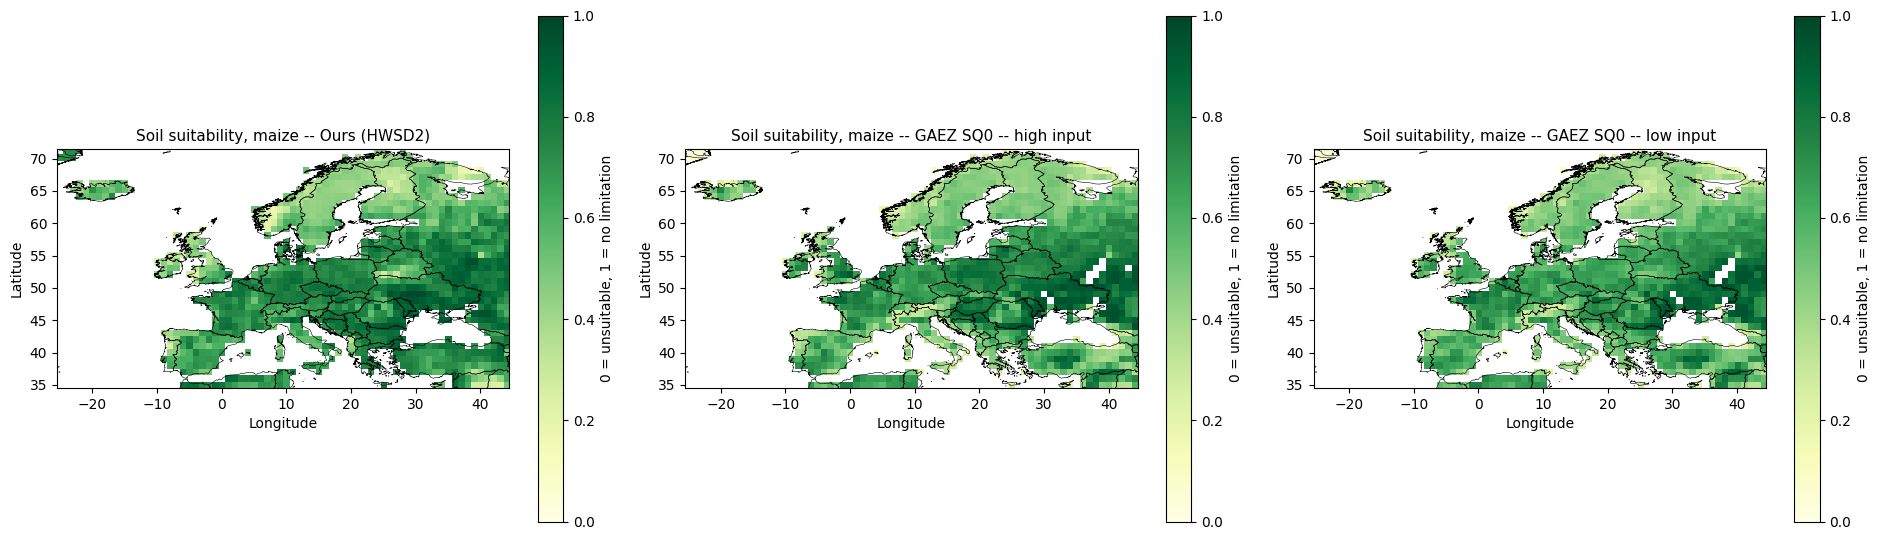

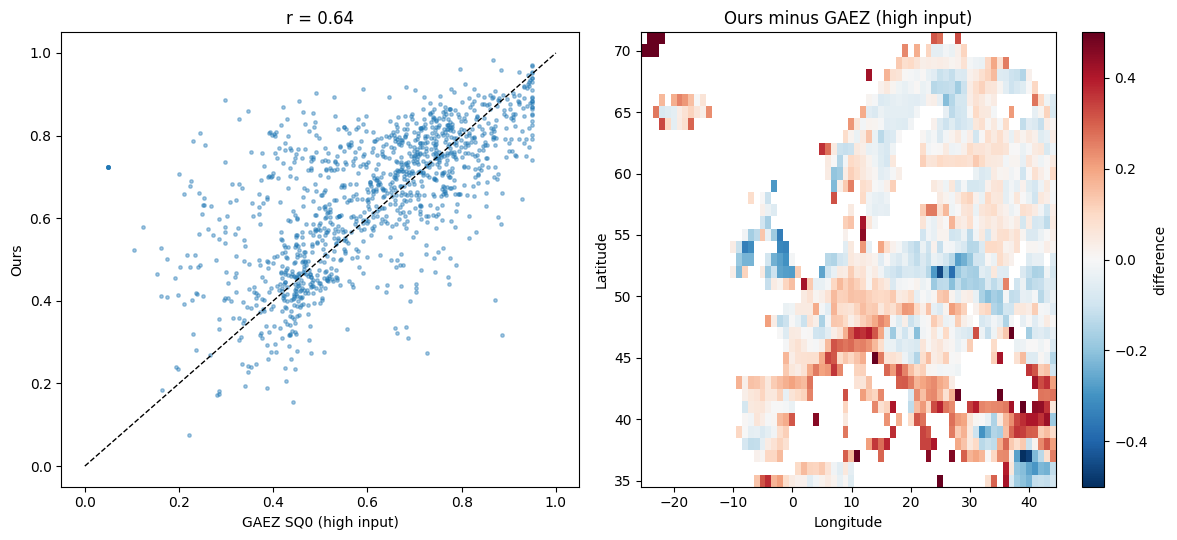

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
fig.subplots_adjust(left=0.045)
for ax, arr, title in zip(axes, [our_idx, gaez_H, gaez_L],
                          ['Ours (HWSD2)', 'GAEZ SQ0 -- high input', 'GAEZ SQ0 -- low input']):
    im = ax.imshow(arr, origin='lower', aspect='auto', extent=ext, cmap='YlGn', vmin=0, vmax=1)
    ax.set_title(f'Soil suitability, maize -- {title}', fontsize=11)
    plt.colorbar(im, ax=ax, label='0 = unsuitable, 1 = no limitation')
    ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
    add_coastlines(ax)
plt.tight_layout()
plt.savefig(OUT_DIR / 'soil_validation_maps.png', dpi=130)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
axes[0].scatter(gaez_H[both], our_idx[both], s=6, alpha=0.4)
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_xlabel('GAEZ SQ0 (high input)'); axes[0].set_ylabel('Ours'); axes[0].set_title(f'r = {r_H:.2f}')
diff = our_idx - gaez_H
im = axes[1].imshow(diff, origin='lower', aspect='auto', extent=ext, cmap='RdBu_r', vmin=-0.5, vmax=0.5)
axes[1].set_title('Ours minus GAEZ (high input)')
plt.colorbar(im, ax=axes[1], label='difference')
axes[1].set_xlabel('Longitude'); axes[1].set_ylabel('Latitude')
plt.tight_layout()
plt.savefig(OUT_DIR / 'soil_validation_scatter.png', dpi=130)
plt.show()

### Binary version (suitable / not suitable)

Same three panels, thresholded at `TAU_MAP` (Sys 1993 S3/N1 boundary, 0.4) for our index; the two GAEZ SQ0 panels are decoded from the same 0-1 band-midpoint score and thresholded identically, so the three maps are directly comparable even though GAEZ was not built with this threshold in mind.

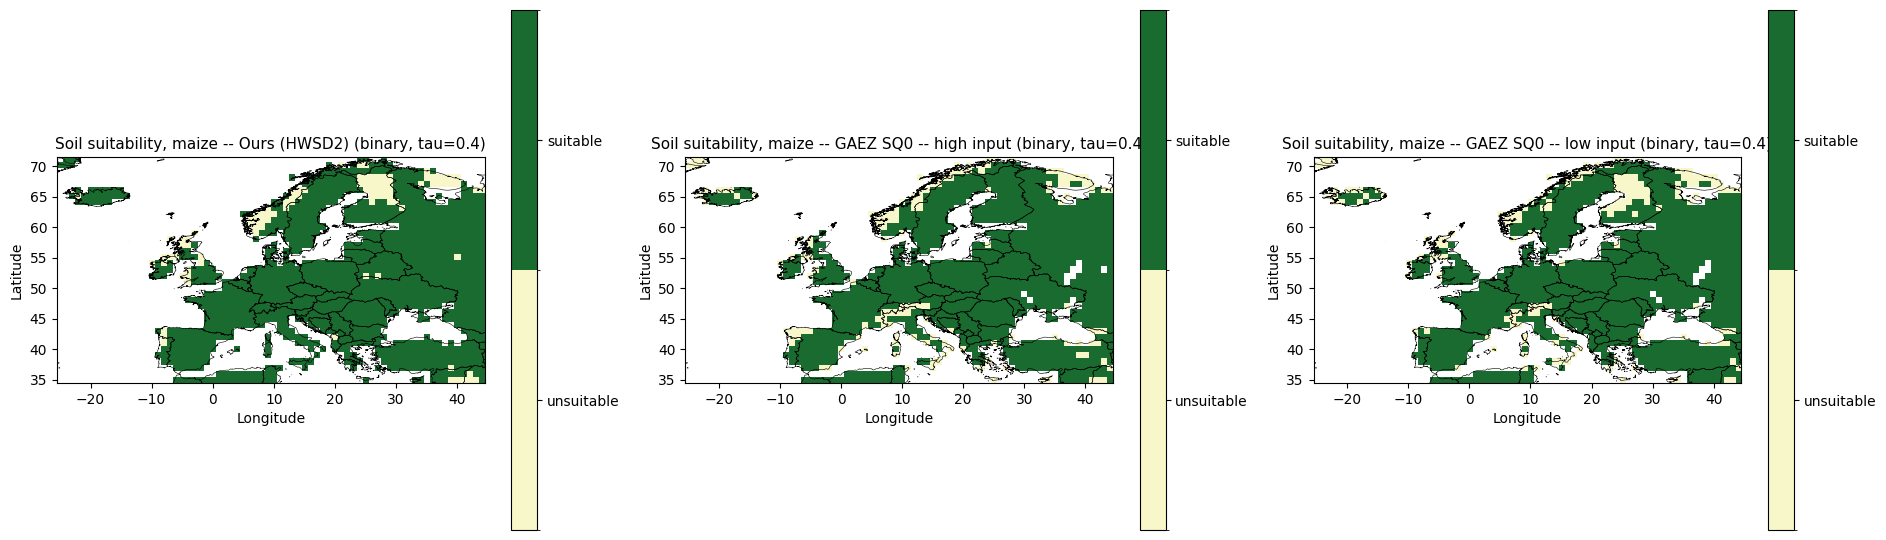

In [7]:
from matplotlib.colors import ListedColormap, BoundaryNorm
ds_s = xr.open_dataset(SOIL_NC)
TAU_MAP = float(ds_s.attrs['tau_map']); ds_s.close()

bin_cmap = ListedColormap(['#f7f7c9', '#1a6b2f'])   # unsuitable, suitable
bin_norm = BoundaryNorm([0, 0.5, 1], bin_cmap.N)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
fig.subplots_adjust(left=0.045)
for ax, arr, title in zip(axes, [our_idx, gaez_H, gaez_L],
                          ['Ours (HWSD2)', 'GAEZ SQ0 -- high input', 'GAEZ SQ0 -- low input']):
    binary = np.where(np.isfinite(arr), (arr >= TAU_MAP).astype(float), np.nan)
    im = ax.imshow(binary, origin='lower', aspect='auto', extent=ext, cmap=bin_cmap, norm=bin_norm)
    ax.set_title('Soil suitability, maize -- ' + title + f' (binary, tau={TAU_MAP:.1f})', fontsize=11)
    cbar = plt.colorbar(im, ax=ax, ticks=[0.25, 0.75])
    cbar.ax.set_yticklabels(['unsuitable', 'suitable'])
    ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
    add_coastlines(ax)
plt.tight_layout()
plt.savefig(OUT_DIR / 'soil_validation_maps_binary.png', dpi=130)
plt.show()

**Reading this comparison:** a moderate-to-strong positive correlation with GAEZ's independently
computed soil layer, using an independently-built rating system (FAO's SQ1-SQ7 soil qualities vs
our Sys 1993 rules) on the same underlying HWSD data, is the relevant signal here — perfect
agreement is not expected (different characteristics weighted differently, different depth/texture
handling, "high input" vs "low input" GAEZ variants bracket a management assumption we do not
make). Large, spatially coherent disagreement (not just scatter) would be the sign to look at more
closely; scattered/local disagreement is expected given the two methods rate somewhat different
things. A full attempt to replicate GAEZ's own combination methodology end-to-end (not just this
comparison) was also made and is documented in the report (Section 7.8) rather than kept as
active code — it validated worse than this simpler layer and was not adopted.

## Soil layer vs currently cultivated pixels (MIRCA2000 crop presence)

Sanity check: a well-calibrated soil layer should rate *currently cultivated* pixels as more suitable than the rest of the land. "Cultivated" = MIRCA2000 crop presence (0.25° spatial mask, read directly and reduced to the 1° grid: a 1° cell counts as cultivated if at least one 0.25° sub-pixel has the crop, the same rule as in step 1); "background" = every other land cell of the soil layer. Reported for the old dominant-unit binary layer and for the index (mean value, and share of cells below `TAU_MAP`). This does **not** replace review against the literature — it only checks that the layer is directionally sane.

In [8]:
import rasterio
ds_s = xr.open_dataset(SOIL_NC)
TAU_MAP = float(ds_s.attrs['tau_map'])
CROPS = {'Maize_rf': 'Maize', 'Wheat-spring_rf': 'Wheat-spring', 'Wheat-winter_rf': 'Wheat-winter'}
soil_suit_frac = {c: ds_s[f'soil_suit_idx_{c}'].values for c in CROPS}
soil_suit_bin_dominant = {c: ds_s[f'soil_suit_bin_dominant_{c}'].values for c in CROPS}
ds_s.close()

MIRCA_DIR = BASE / "0_Input_data" / "masks_crops" / "_archive_0.25deg_old_masks" / "spatial"
LAT_025 = np.linspace(89.875, -89.875, 720)
LON_025 = np.linspace(-179.875, 179.875, 1440)

def mirca_presence_1deg(tif_path):
    """MIRCA2000 0.25deg presence -> 1deg: 1 if any sub-pixel in the cell has the crop."""
    with rasterio.open(tif_path) as src:
        d = src.read(1).astype(float); nd = src.nodata
    if nd is not None: d[d == nd] = np.nan
    out = np.zeros((len(target_lats_asc), len(target_lons)), dtype=bool)
    for i, la in enumerate(target_lats_asc):
        rm = (LAT_025 >= la - 0.5) & (LAT_025 < la + 0.5)
        for j, lo in enumerate(target_lons):
            cm = (LON_025 >= lo - 0.5) & (LON_025 < lo + 0.5)
            out[i, j] = np.nanmax(d[np.ix_(rm, cm)]) == 1 if np.isfinite(d[np.ix_(rm, cm)]).any() else False
    return out

hdr = (f'{"Crop":18s} | {"dominant-unit: excluded %":^26s} | {"index: mean value":^21s} | '
       f'{"index < TAU: excluded %":^27s} | {"cells":^13s}')
print(hdr); print(f'{"":18s} | {"cultivated":>12s} {"background":>12s} | {"cultivated":>10s} {"backgr.":>10s} | '
                  f'{"cultivated":>12s} {"background":>13s} | {"cult./backgr.":>13s}')
print('-' * len(hdr))
for crop, mname in CROPS.items():
    pres_mask = mirca_presence_1deg(MIRCA_DIR / f'{mname}_mask.tif')
    frac, dom = soil_suit_frac[crop], soil_suit_bin_dominant[crop]
    land = np.isfinite(frac)
    P, B = land & pres_mask, land & ~pres_mask
    print(f'{crop:18s} | {100*(dom[P]==0).mean():11.1f}% {100*(dom[B]==0).mean():11.1f}% | '
          f'{frac[P].mean():10.3f} {frac[B].mean():10.3f} | '
          f'{100*(frac[P]<TAU_MAP).mean():11.1f}% {100*(frac[B]<TAU_MAP).mean():12.1f}% | {int(P.sum()):5d}/{int(B.sum()):<5d}')


Crop               | dominant-unit: excluded %  |   index: mean value   |   index < TAU: excluded %   |     cells    
                   |   cultivated   background | cultivated    backgr. |   cultivated    background | cult./backgr.
---------------------------------------------------------------------------------------------------------------------
Maize_rf           |        13.4%        15.1% |      0.727      0.597 |         1.9%         11.8% |   485/736  
Wheat-spring_rf    |        11.1%        28.8% |      0.719      0.460 |         3.5%         32.1% |   891/330  
Wheat-winter_rf    |        11.1%        28.8% |      0.719      0.460 |         3.5%         32.1% |   891/330  
